In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import testis_model as tm
importlib.reload(tm)

<module 'testis_model' from '/Users/connor/Documents/github/sperm-data-analysis/testis_model/__init__.py'>

In [51]:
importlib.reload(tm.gillespie)
importlib.reload(tm.data_processing)

n_stem = 1000
n_clones = 2
r_event = 36

p_asymmetric = (36 - 4)/36

eff_drift = r_event * (1 - p_asymmetric)
p_diff = 1 - p_asymmetric

sperm_per_diff = 1300
r_decay = 7
tau = 0.2

rng = np.random.default_rng()
init_freq = np.array([0.5, 0.5])
hmm = tm.gillespie.AdvancedTestisModel(n_stem, n_clones, r_event, p_diff, r_decay, tau, sperm_per_diff, init_freq)

In [52]:
# sample_times = np.sort(np.array(list(tm.data_processing.sample_map_int.values())))
sample_times = np.arange(5, 20)
sample_times = np.repeat(sample_times, 3)

In [53]:
# sample_times = np.arange(1, 16)
n_sperm = 371

samples, record, mean = hmm.simulate_gillespie(sample_times, n_sperm = 371, rng = rng, init_time = 4)

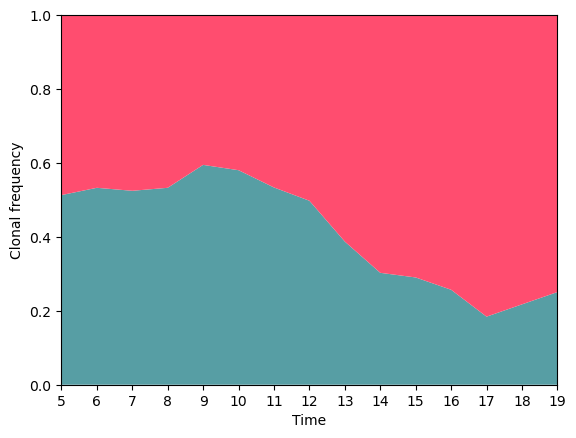

In [54]:
importlib.reload(tm.visualize)
tm.visualize.plot(samples)

In [49]:
importlib.reload(tm.likelihood)
lm = tm.likelihood.LikelihoodModel(n_stem)

In [55]:
lm.max_likelihood(samples, statistic = 4)

(np.float64(5.7298488952092645),
 np.float64(-188.91304764110075),
 2.76835880799797,
 13.88140529428139)

In [210]:
lm.likelihood(samples, 25.06, init_freq, init_time = 4)

np.float64(-226.69040504904027)

In [10]:
lm.max_likelihood_null(samples, init_time = 4)

(np.float64(0.47698430578699785), np.float64(-592.6952598843643))

In [32]:
%%time
lm.max_likelihood(samples, init_time = 4, statistic = 4, f_cutoff=1e-10)

CPU times: user 17.6 s, sys: 5.36 s, total: 23 s
Wall time: 3.09 s


(np.float64(3.627386369303104),
 np.float64(-182.4197862999557),
 1.6425522975987688,
 9.268478437543196)

In [193]:
lm.likelihood(samples, 2.160412, init_freq)

np.float64(-221.28095078158088)

In [106]:
lm.likelihood(samples, 14, 0.42)

np.float64(-133.20386287657655)

In [109]:
lm.likelihood(samples, 0, init_freq)

np.float64(-4181.555176330228)

In [119]:
%%time
r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(samples, init_time = 4, statistic = 4)
print(f'{r_opt:.3f}, {if_opt:.3f}, {l_max:.3f}, {lower:.3f}, {upper:.3f}')

13.106, 0.420, -132.380, 6.349, 30.645
CPU times: user 19.9 s, sys: 1.75 s, total: 21.7 s
Wall time: 2.96 s


In [122]:
lm.likelihood(samples, 6.349, 0.42, init_time = 4)

np.float64(-134.38054624300358)

In [22]:
%%time
r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(samples, init_time = 4)
print(f'{r_opt:.3f}, {if_opt:.3f}, {l_max:.3f}, {lower:.3f}, {upper:.3f}')

7.928, 0.594, -219.839, 3.177, 24.922
CPU times: user 24.3 s, sys: 4 s, total: 28.3 s
Wall time: 4.27 s


In [205]:
def sim_study(r, n_sims):
    n_stem = 1000
    n_clones = 2
    r_event = 36
    
    p_asymmetric = (36 - r) / r_event
    
    eff_drift = r_event * (1 - p_asymmetric)
    p_diff = q_div = (1 - p_asymmetric) / 2
    
    sperm_per_diff = 1300
    r_decay = 6.28
    init_freq = np.array([0.5, 0.5])
    
    n_sperm = 371
    
    hmm = tm.gillespie.AdvancedTestisModel(n_stem, n_clones, r_event, p_diff, q_div, r_decay, sperm_per_diff, init_freq)
    lm = tm.likelihood.LikelihoodModel(n_stem)

    r_maxes = []
    l_gaps = []
    uppers = []
    lowers = []
    for i in range(n_sims):
        rng = np.random.default_rng(i)
        sample_times = np.arange(1, 16)

        samples, record, mean = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
        r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(samples, statistic = 4)
        l_null = lm.likelihood(samples, 0, init_freq = np.ones(n_stem + 1)/(n_stem + 1))

        l_gaps.append(l_max - l_null)
        r_maxes.append(r_opt)
        uppers.append(upper)
        lowers.append(lower)

    return np.array(r_maxes), np.array(l_gaps), np.array(uppers), np.array(lowers)

In [206]:
%%time
from joblib import Parallel, delayed

# Define the r values and fixed second argument
r_values = [0.1, 1, 4, 9, 15, 36]
n_sims = 100

# Run in parallel
r_maxes = Parallel(n_jobs=-1)(delayed(sim_study)(r, n_sims) for r in r_values)

CPU times: user 622 ms, sys: 266 ms, total: 888 ms
Wall time: 6min 53s


In [207]:
for i in range(len(r_values)):
    rm = r_maxes[i][0]
    lg = r_maxes[i][1]
    upper = r_maxes[i][2]
    lower = r_maxes[i][3]

    rs = np.linspace(0, 50, 500)
    ys = np.zeros_like(rs)
    
    f = lambda x: np.mean((lower < x) & (upper > x))
    
    for j, r in enumerate(rs):
        ys[j] = f(r)
    
    idx = np.argmax(ys)
    
    print(f'r = {r_values[i]:.2f}:\t {np.mean(rm):.2f} +/- {np.std(rm)/np.sqrt(n_sims):.2f}')
    print(rs[idx], ys[idx])
    print('true: ', f(r_values[i]))
    print()

r = 0.10:	 0.20 +/- 0.03
0.20040080160320642 1.0
true:  0.99

r = 1.00:	 0.98 +/- 0.08
0.8016032064128257 0.95
true:  0.94

r = 4.00:	 3.27 +/- 0.18
2.905811623246493 0.96
true:  0.95

r = 9.00:	 7.52 +/- 0.34
7.3146292585170345 0.97
true:  0.95

r = 15.00:	 13.66 +/- 0.69
12.024048096192384 0.96
true:  0.96

r = 36.00:	 33.95 +/- 2.06
29.158316633266534 0.97
true:  0.92



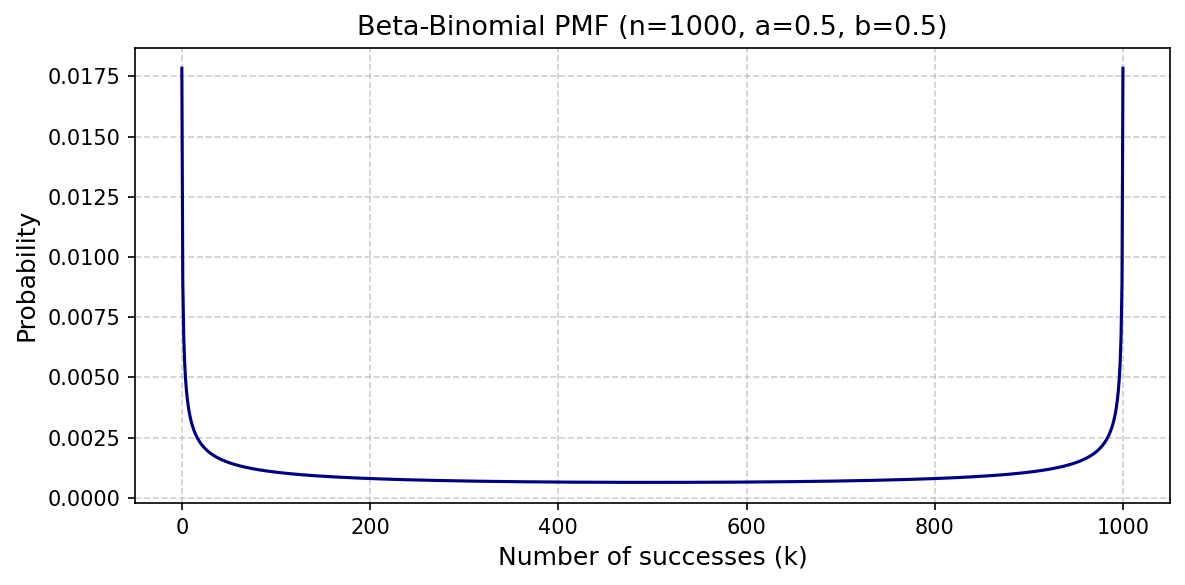

In [208]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import betabinom

# Parameters
n = 1000
a, b = 0.5, 0.5

# Support values: 0 through n
x = np.arange(n + 1)

# PMF
pmf = betabinom.pmf(x, n, a, b)

# Plot
plt.figure(figsize=(8,4), dpi=150)
plt.plot(x, pmf, color='navy', lw=1.5)
plt.title(f"Beta-Binomial PMF (n={n}, a={a}, b={b})", fontsize=13)
plt.xlabel("Number of successes (k)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()